
# MODULE 35.6 — MEL-FREQUENCY CEPSTRAL COEFFICIENTS (MFCC)

**High priority**

## 1. What are MFCCs?

MFCC stands for **Mel-Frequency Cepstral Coefficients**.

They are compact numerical features that describe the spectral characteristics of speech.

Common applications include:

- Speech Emotion Recognition (SER).
- Automatic Speech Recognition (ASR).
- Speaker Recognition.
- Speech Classification.
- Audio Pattern Recognition.

### Why do we need MFCCs?

In Module 35.5, we generated Log-Mel spectrograms.

Suppose we have a recording with:

- 40 Mel bands.
- 401 time frames.

Its Log-Mel representation has the shape:

$$
40 \times 401
$$

That means every frame contains 40 Mel-band values.

What if we want a more compact representation?

MFCCs apply another mathematical transformation to the Log-Mel features, producing a smaller set of coefficients.

For example:

$$
MFCC \in \mathbb{R}^{13 \times 401}
$$

Instead of retaining all 40 Mel-band values, we retain 13 cepstral coefficients per frame.

**Important:** MFCCs are not simply a smaller Mel spectrogram. They are a transformed representation of the log Mel spectrum.

![Enhanced Conformer-Based Speech Recognition via Model Fusion and Adaptive Decoding with Dynamic Rescoring](https://images.openai.com/static-rsc-4/x9EYVEKW8f6smZQe-9LTyf1PqTQpvh4muqp06Ai2GLA_c2KsDL4ZHCNJhzQdAPXbMXdQJjztzfj_qAHWITGq0ST3pxRQ7FpmcncQsiQg5_48-cy2uUMGTf-KjSP_9pAc8dMGXEz9eAqi4VN8VUU41ZnnZKnvjdYdyBhOPxyiPpE?purpose=inline)

[Source: MDPI](https://www.mdpi.com/2076-3417/14/24/11583?utm_source=chatgpt.com)

## 2. What are cepstrum and cepstral representation?

**Must Know**

Before understanding MFCC, we need to understand the word *cepstrum*.

The cepstrum is a representation obtained by taking the inverse Fourier transform of the logarithm of a spectrum.

In simplified form:

$$
c[n] = \mathcal{F}^{-1}\{\log |X[k]|\}
$$

Where:

- $X[k]$ = frequency spectrum.
- $\log |X[k]|$ = log magnitude spectrum.
- $c[n]$ = cepstral representation.

The original cepstrum uses an inverse Fourier transform. MFCCs use a Discrete Cosine Transform (DCT) on log Mel filter-bank energies to obtain a related, compact cepstral representation.

### Why is this useful?

Speech signals contain different spectral characteristics arising from:

- Vocal fold excitation.
- Vocal tract characteristics.
- Articulation.
- Phonetic content.
- Speaker characteristics.

Cepstral representations help describe the broad spectral envelope of speech.

For SER, this can provide useful information about vocal quality and spectral characteristics.

### What does the word cepstrum mean?

It is actually a playful rearrangement of the word *spectrum*.

| Signal-processing term | Cepstral terminology |
| ---------------------- | -------------------- |
| Frequency              | Quefrency            |
| Spectrum               | Cepstrum             |
| Filtering              | Liftering            |

You don't need to memorize every cepstral terminology detail for our project. Understand the transformation and its purpose.

## 3. MFCC versus Mel spectrogram

**Must Know**

Let's compare the two representations.

![How to build your own wake word detector](https://images.openai.com/static-rsc-4/24EDW0FzXg5dn7iDFNsaENP4raEqg0YYnFc2lCWTWYRfwHOk8yqoOCQlXZF2BAv9Zx9gJdtT7rRkfiRDmAxLcxyoXP7q98fWVnxWKa-zpHDb0e0fSTDKCqgNJzANTyY3WSqNFuGOUEOPXcSj7cbe35vmDKuJ1mgaEODbZkwJEjo?purpose=inline)

**Log-Mel spectrogram**

Energy across Mel frequency bands and time.

![Multi-Label Emotion Recognition of Korean Speech Data Using Deep Fusion Models](https://images.openai.com/static-rsc-4/K8e2AjvopGfEuNyoop0xQ1Vaf_4qzRPJZSsUZMKmOFaizQAXTW-d4-wr8djUM2xkCsFpVSecoL6BIwQm7dFwHqRFouuJtdUCmgBfS2Jfq_z0BiJxcnY33hqQEdNV6uSQEzo3xc5e5SfE0cvaPAHs4tyZ2OsFC7ypdtjkAfv7eoA?purpose=inline)

**MFCC**

Cepstral coefficients across time.

| Property       | Log-Mel spectrogram                   | MFCC                                |
| -------------- | ------------------------------------- | ----------------------------------- |
| Input          | Mel filter-bank energies              | Log Mel energies                    |
| Transformation | Logarithmic compression               | DCT after logarithmic compression   |
| Output         | Mel-band values                       | Cepstral coefficients               |
| Dimensions     | Number of Mel bands × frames          | Number of MFCCs × frames            |
| Information    | More detailed Mel-band representation | Compact spectral representation     |
| Common use     | CNN-based speech and audio models     | Classical ML and speech recognition |

### Why are MFCCs useful as compact speech features?

The DCT transforms the Mel-band values into coefficients representing broad patterns in their distribution.

Lower-order coefficients generally capture broad variations in the spectral envelope, while higher-order coefficients represent finer variations.

By retaining a limited number of coefficients, we can reduce the feature dimension.

However, this also discards some spectral detail.

**Important for SER:** A compact representation isn't automatically better. We'll compare MFCC and Log-Mel performance rather than assuming MFCC always wins.

## 4. Complete MFCC extraction pipeline

**Must Know**

Here is the complete pipeline.

1. **Raw audio waveform**
2. **Pre-emphasis (optional)**
3. **Framing and windowing**
4. **FFT → Power spectrum**
5. **Mel filter bank**
6. **Logarithmic compression**
7. **Discrete Cosine Transform (DCT)**
8. **MFCC coefficients**

Let's understand the important stages.

### 4.1 Pre-emphasis (optional)

**Good to Know**

Pre-emphasis is a filtering operation that boosts higher-frequency components relative to lower-frequency components.

A common first-order filter is:

$$
y[n] = x[n]-\alpha x[n-1]
$$

Where:

- $x[n]$ = original signal.
- $y[n]$ = pre-emphasized signal.
- $\alpha$ = pre-emphasis coefficient, commonly around 0.95 to 0.97.

Python:

```python
alpha = 0.97

emphasized_audio = librosa.effects.preemphasis(
    audio,
    coef=alpha
)
```

Why was this traditionally used?

Speech spectra often have a downward spectral tilt, meaning higher-frequency components tend to have lower energy.

Pre-emphasis compensates for some of that tilt.

**Do we need it in our SER project?**

Not necessarily.

Modern pipelines often omit pre-emphasis, especially when using learned representations or when the preprocessing configuration has already been optimized.

We'll keep it optional and compare its effect only if useful.

### 4.2 Framing and windowing

We've already studied this in Module 34 and used it in Module 35.

Briefly:

- Divide audio into overlapping frames.
- Apply a window function.
- Calculate the frequency representation of each frame.

For our baseline:

```python
SR = 16000

N_FFT = 512
WIN_LENGTH = 400
HOP_LENGTH = 160
```

### 4.3 Power spectrum

Calculate the squared magnitude of the STFT:

$$
P(k,t)=|X(k,t)|^2
$$

### 4.4 Mel filter banks

Apply triangular Mel filters to group frequency-bin information.

$$
M(b,t)=\sum_k H_b(k)P(k,t)
$$

### 4.5 Logarithmic compression

Apply a logarithm:

$$
L(b,t)=\log(M(b,t)+\epsilon)
$$

### 4.6 Discrete Cosine Transform (DCT)

Now comes the most important MFCC operation.

## 5. Discrete Cosine Transform (DCT)

**Must Know**

We have our Log-Mel representation.

Suppose a particular frame contains 40 log Mel values:

$$
L=[L_1,L_2,\ldots,L_{40}]
$$

We apply the DCT to transform these values into cepstral coefficients.

A common DCT-II formulation is:

$$
C_n = \sum_{m=0}^{M-1} L_m
\cos\left[
\frac{\pi n}{M}
\left(m+\frac{1}{2}\right)
\right]
$$

Where:

- $C_n$ = MFCC coefficient.
- $L_m$ = log Mel energy of band $m$.
- $M$ = number of Mel bands.
- $n$ = coefficient index.

In practice, normalization constants are also applied.

### Why do we use DCT?

The DCT converts the log Mel-band values into a different coordinate representation.

This allows us to describe broad spectral-envelope patterns using relatively few coefficients.

Think about it this way:

- Log-Mel gives us the energy of each Mel band.
- DCT reorganizes those values into cepstral coefficients.
- We retain selected coefficients to obtain a compact feature representation.

![TensorFlow Lite Tutorial Part 1: Wake Word Feature Extraction](https://images.openai.com/static-rsc-4/PmAyTbyKNFpdY-3XWpeiRvvhtfqkadj9817acXAJNzl1vcZLmvTjpILvSfY1_6__waLILqoWcXFW5TioD8IPu9yeBcwoYlFK8iKPB-Bloe2-E3ji4JZYII5HYipFj0fPublQI_vP9NvXFPcS8qasy6w4Hqs1I-RYSazb9Bg6YG0?purpose=inline)

[Source: DigiKey](https://www.digikey.com/en/maker/projects/tensorflow-lite-tutorial-part-1-wake-word-feature-extraction/54e1ce8520154081a58feb301ef9d87a?utm_source=chatgpt.com)

### Important distinction

DCT is not reducing the number of values by itself.

If we apply a 40-point DCT to 40 Mel-band values, we still obtain 40 coefficients.

We reduce dimensionality by retaining only the first selected coefficients.

For example:

$$
40 \text{ Mel values}
\xrightarrow{DCT}
40 \text{ coefficients}
$$

Then:

$$
40 \text{ coefficients}
\rightarrow
13 \text{ selected coefficients}
$$

This is where dimensionality reduction occurs.

## 6. MFCC coefficient matrix

**Must Know**

MFCC extraction is performed independently for every frame.

Suppose:

- Number of Mel bands = 40.
- Number of retained MFCC coefficients = 13.
- Number of time frames = 401.

The resulting MFCC matrix is:

$$
MFCC \in \mathbb{R}^{13\times401}
$$

![Speech Processing for Machine Learning: Filter banks, Mel-Frequency Cepstral Coefficients (MFCCs) and What's In-Between](https://images.openai.com/static-rsc-4/17ioILQ7OVGhWyA-vI7O4vlRQ5yATAJxzGrNNaU13Zv_fAbTWbIBSUrrPbNvy7jTg1U7TsAe4OQKu9doneM6buKvZYOySoglvAjhFIJlOogpj_ufYUdVYjqpAtKTlDCrer7OI35HdsFhwWO0jJgLGqbe0rXvtY2iPxgoN1mraEs?purpose=inline)

[Source: Haytham Fayek](https://haythamfayek.com/2016/04/21/speech-processing-for-machine-learning.html?utm_source=chatgpt.com)

Each column represents the cepstral coefficients of one audio frame.

Each row represents one MFCC coefficient evolving over time.

For example:

| Coefficient | Frame 1 | Frame 2 | Frame 3 |
| ----------- | ------- | ------- | ------- |
| MFCC 0      | -250    | -240    | -235    |
| MFCC 1      | 15      | 18      | 16      |
| MFCC 2      | -5      | -4      | -3       |
| MFCC 3      | 8       | 9       | 7       |
| ...         | ...     | ...     | ...     |
| MFCC 12     | 1.2     | 1.5     | 1.1     |

These are illustrative values.

## 7. Number of MFCC coefficients

**Must Know**

Common configurations include:

| MFCC coefficients | Typical use                                 |
| ----------------- | ------------------------------------------- |
| 12                | Compact representation                      |
| 13                | Traditional speech-processing configuration |
| 20                | More cepstral detail                        |
| 26                | Higher-dimensional representation           |
| 40                | Retaining more coefficients                 |

For our first SER baseline, we'll use:

```python
N_MFCC = 13
N_MELS = 40
```

Why 13?

It is a commonly used traditional speech-processing configuration that offers a compact representation.

But don't treat 13 as a universal optimum.

We can compare 13, 20 and 26 coefficients experimentally.

## 8. C0 and higher-order coefficients

**Must Know**

Let's understand what the individual coefficients represent.

### C0 — Zeroth MFCC coefficient

C0 is related to the overall log Mel spectral energy.

Its precise interpretation depends on the DCT convention and whether the implementation includes or replaces the zeroth coefficient with log energy.

In many traditional speech-processing pipelines, C0 is retained as an energy-related feature.

In some configurations, it is excluded or replaced with a separately calculated log-energy value.

### Higher-order coefficients

- Lower-order coefficients describe broad variations in the spectral envelope.
- Higher-order coefficients capture finer variations in the cepstral representation.

![An introduction to audio processing and machine learning using Python](https://images.openai.com/static-rsc-4/zm3HtzgROfjG9nxAy1bqYs-g0HICwl8N3sBIdgF4SpBOXceDX9gtwHXQzKzpaDlaOlbwRwWQrTQP9Tbm9TiXaOUruvEasS9tMxSpxRoqWWqTwLUY110-SdxCmUG2tD9Wv4LYB58FvXrTlTTvQMAxjqGCaJ0Paeb_FkZWhiT0vvg?purpose=inline)

[Source: Opensource.com](https://opensource.com/article/19/9/audio-processing-machine-learning-python?utm_source=chatgpt.com)

**SER relevance:**

The coefficients collectively describe vocal spectral characteristics.

However, individual coefficients should not be interpreted as direct emotion measurements.

For example, MFCC 1 does not represent happiness, and MFCC 2 does not represent anger.

Emotion classification depends on learned combinations of features.

## 9. Delta MFCC

**Must Know**

Normal MFCCs describe spectral characteristics at individual frames.

But speech changes over time.

Delta MFCCs represent the temporal change in MFCC coefficients.

In simpler terms:

> Delta MFCCs describe how the MFCC values are changing across neighbouring frames.

A common delta calculation is:

$$
\Delta c_t =
\frac{
\sum_{n=1}^{N}n(c_{t+n}-c_{t-n})
}{
2\sum_{n=1}^{N}n^2
}
$$

Where:

- $c_t$ = MFCC coefficient at frame $t$.
- $N$ = number of neighbouring frames used.
- $\Delta c_t$ = first-order temporal derivative.

### Intuition

Imagine one MFCC coefficient:

$$
[2,4,7,11,16]
$$

The values are increasing over time.

Delta MFCCs capture this changing behaviour.

They are useful for representing temporal characteristics that static MFCCs do not explicitly describe.

### Python implementation

```python
delta_mfcc = librosa.feature.delta(
    mfcc,
    order=1
)
```

## 10. Delta-Delta MFCC

**Must Know**

Delta-Delta MFCCs are second-order temporal derivatives.

They describe how the delta values themselves change.

In simple terms:

- MFCC: What are the spectral characteristics?
- Delta: How are those characteristics changing?
- Delta-Delta: How is the rate of change itself changing?

Mathematically:

$$
\Delta^2 c_t = \Delta(\Delta c_t)
$$

Python:

```python
delta2_mfcc = librosa.feature.delta(
    mfcc,
    order=2
)
```

### Compare the three representations

![librosa.feature.delta documentation](https://images.openai.com/static-rsc-4/bGrYusPxRdsatQmHFPVdlczV1mlkS2RI9KFPC1k4yakOW95ojUtmVviZnWC1xHCNcPukOTijKBsrLQZ-za8HbxGLsFckn8Mb8Wp3LJQflHUjcSR9aBWxhg8NhT1PoUi46VXwXHxkbu8lt4ckfNfNu3JtAWaNjqtJ9utxF1Skynk?purpose=inline)

[Source: librosa documentation](https://librosa.org/doc/latest/generated/librosa.feature.delta.html?utm_source=chatgpt.com)

| Feature          | Information                     |
| ---------------- | ------------------------------- |
| MFCC             | Static spectral characteristics |
| Delta MFCC       | First-order temporal changes    |
| Delta-Delta MFCC | Second-order temporal changes   |

If we retain 13 coefficients for each representation:

$$
13+13+13=39
$$

Our combined feature matrix becomes:

$$
39\times401
$$

This provides more temporal information, but also increases dimensionality and potentially introduces redundancy.

## 11. Cepstral Mean Normalization (CMN)

**Good to Know**

Different recordings can have different average cepstral values.

This may happen due to:

- Microphone characteristics.
- Recording conditions.
- Speaker differences.
- Channel effects.

Cepstral Mean Normalization removes the mean of each MFCC coefficient across the frames of an utterance.

$$
c'_{i,t}=c_{i,t}-\mu_i
$$

Where:

- $c_{i,t}$ = coefficient $i$ at frame $t$.
- $\mu_i$ = mean of coefficient $i$ across time.
- $c'_{i,t}$ = normalized coefficient.

Python:

```python
mfcc_cmn = mfcc - np.mean(
    mfcc,
    axis=1,
    keepdims=True
)
```

This is called utterance-level CMN.

### Limitation for SER

Removing the mean can also remove useful information.

For example, absolute spectral characteristics might contain emotion-related information.

Therefore, we should compare MFCCs with and without CMN rather than automatically applying it.

## 12. Cepstral Mean and Variance Normalization (CMVN)

**Good to Know**

CMVN goes one step further.

It removes the mean and scales by the standard deviation.

$$
c'_{i,t}=
\frac{c_{i,t}-\mu_i}{\sigma_i+\epsilon}
$$

Where:

- $\mu_i$ = mean of coefficient $i$.
- $\sigma_i$ = standard deviation of coefficient $i$.
- $\epsilon$ = small constant.

Python:

```python
mfcc_cmvn = (
    mfcc - np.mean(mfcc, axis=1, keepdims=True)
) / (
    np.std(mfcc, axis=1, keepdims=True) + 1e-8
)
```

### CMN versus CMVN

| Method | Operation                                   |
| ------ | ------------------------------------------- |
| CMN    | Mean subtraction                            |
| CMVN   | Mean subtraction and variance normalization |

**Important SER consideration:** CMN and CMVN can reduce recording-condition variation, but they may also suppress emotional information. We should evaluate their effects empirically.

For dataset-level normalization, calculate statistics from training data only. For utterance-level CMN/CMVN, the statistics are calculated from each individual recording; apply the same procedure consistently during training and inference.





### What should you investigate?

- Which coefficients show different distributions across emotions?
- Which coefficients have substantial overlap?
- Are there unusually large or small values?
- Do the same patterns remain when comparing different speakers?

Don't conclude that a coefficient identifies a particular emotion just because its distributions differ in one dataset.

Also, for model evaluation, use speaker-independent splits when possible. Otherwise, a classifier may learn speaker-specific characteristics instead of emotional patterns.

## 24. MFCC limitations for SER

MFCCs are useful, but they have limitations.

| Limitation              | Explanation                                            |
| ----------------------- | ------------------------------------------------------ |
| Information compression | Some detailed spectral information is discarded        |
| Noise sensitivity       | Background noise affects spectral estimates            |
| Speaker dependency      | Natural voice characteristics influence coefficients   |
| Temporal information    | Static MFCCs alone do not describe how features change |
| Normalization effects   | CMN/CMVN can remove useful emotion-related variation   |
| Coefficient selection   | Too few coefficients may discard useful details        |

This is why we also consider Delta features and Log-Mel spectrograms.

## 25. Final MFCC configuration for our SER experiments

| Parameter         | Initial configuration |
| ----------------- | --------------------- |
| Sampling rate     | 16,000 Hz             |
| Channels          | Mono                  |
| FFT size          | 512                   |
| Window length     | 400                   |
| Hop length        | 160                   |
| Mel bands         | 40                    |
| MFCC coefficients | 13                    |
| DCT type          | Type II               |
| DCT normalization | Ortho                 |
| Delta             | Enabled               |
| Delta-Delta       | Enabled               |
| Pre-emphasis      | Optional              |
| CMN / CMVN        | Experimental          |

**Recommended baseline**

Start with 13 MFCCs, Delta and Delta-Delta. Preserve the original coefficients without CMN/CMVN initially. Compare the variants using the same speaker-independent evaluation splits.

## What you should remember

1. MFCCs are compact cepstral representations derived from Log-Mel filter-bank energies.
2. DCT transforms log Mel values into cepstral coefficients.
3. Retaining only selected coefficients reduces dimensionality.
4. C0 is related to overall log spectral energy, depending on the convention.
5. Delta MFCCs describe first-order temporal changes.
6. Delta-Delta MFCCs describe second-order temporal changes.
7. CMN removes the mean; CMVN removes the mean and normalizes variance.
8. Statistical pooling converts frame-level MFCCs into fixed-length utterance-level vectors.
9. MFCCs compress spectral information, so they should be compared against Log-Mel features.

---

In [1]:
import librosa
import librosa.display

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

In [2]:
SR = 16000

N_FFT = 512
WIN_LENGTH = 400
HOP_LENGTH = 160

N_MELS = 40
N_MFCC = 13

In [3]:
audio, sr = librosa.load(
    "audio/raw/sample-speech-1m.mp3",
    sr=SR,
    mono=True
)

mfcc = librosa.feature.mfcc(
    y=audio,
    sr=sr,
    n_mfcc=N_MFCC,
    n_fft=N_FFT,
    win_length=WIN_LENGTH,
    hop_length=HOP_LENGTH,
    n_mels=N_MELS,
    dct_type=2,
    norm="ortho"
)

print("MFCC shape:", mfcc.shape)

MFCC shape: (13, 6001)


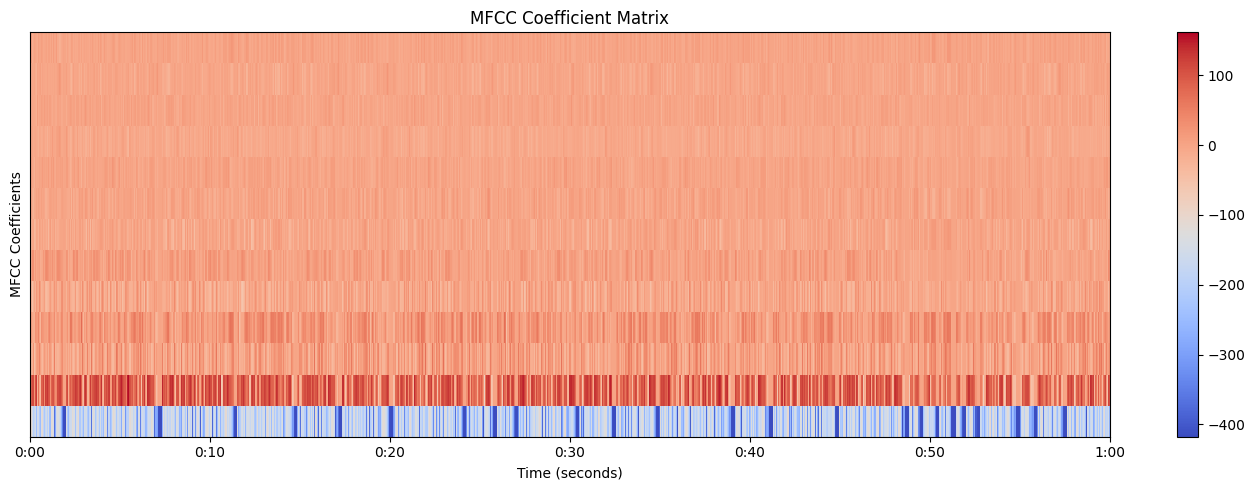

In [4]:
plt.figure(figsize=(14, 5))

librosa.display.specshow(
    mfcc,
    sr=sr,
    hop_length=HOP_LENGTH,
    x_axis="time"
)

plt.colorbar()

plt.title("MFCC Coefficient Matrix")
plt.xlabel("Time (seconds)")
plt.ylabel("MFCC Coefficients")

plt.tight_layout()
plt.show()

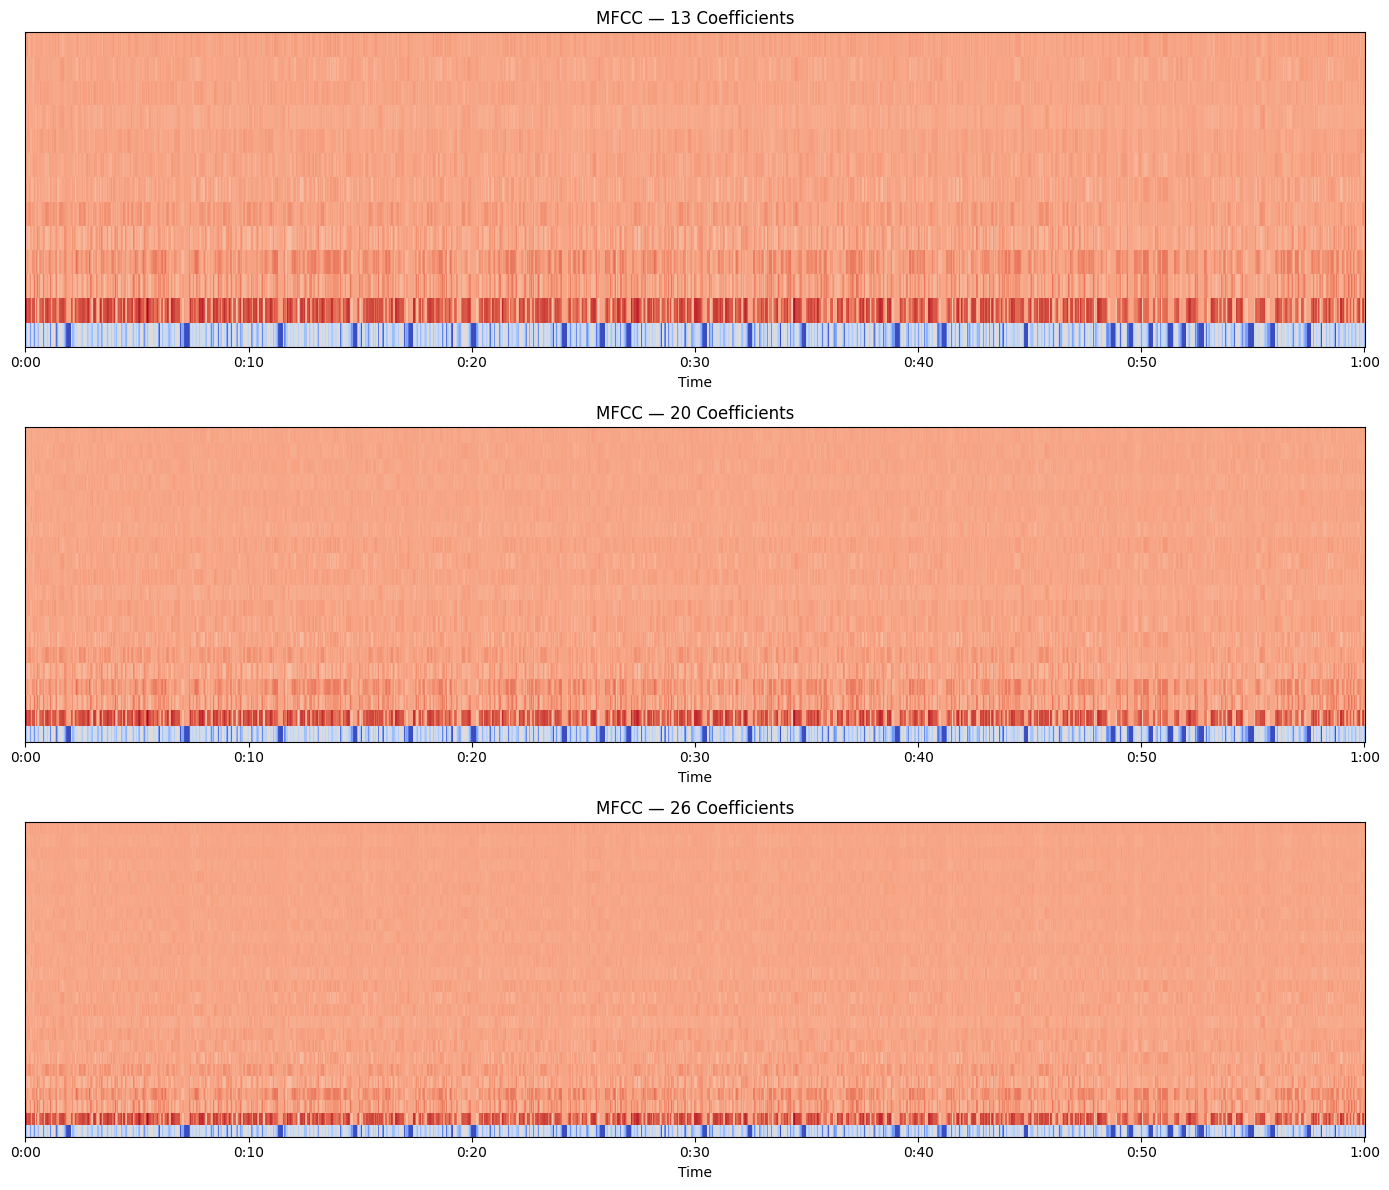

In [5]:
mfcc_counts = [13, 20, 26]

fig, axes = plt.subplots(
    3, 1,
    figsize=(14, 12)
)

for ax, count in zip(axes, mfcc_counts):

    mfcc_temp = librosa.feature.mfcc(
        y=audio,
        sr=sr,
        n_mfcc=count,
        n_fft=N_FFT,
        win_length=WIN_LENGTH,
        hop_length=HOP_LENGTH,
        n_mels=N_MELS
    )

    img = librosa.display.specshow(
        mfcc_temp,
        sr=sr,
        hop_length=HOP_LENGTH,
        x_axis="time",
        ax=ax
    )

    ax.set_title(f"MFCC — {count} Coefficients")

plt.tight_layout()
plt.show()

In [6]:
delta_mfcc = librosa.feature.delta(
    mfcc,
    order=1,
    mode="nearest"
)

In [7]:
delta2_mfcc = librosa.feature.delta(
    mfcc,
    order=2,
    mode="nearest"
)

In [8]:
print("Static MFCC:", mfcc.shape)
print("Delta MFCC:", delta_mfcc.shape)
print("Delta-Delta MFCC:", delta2_mfcc.shape)

Static MFCC: (13, 6001)
Delta MFCC: (13, 6001)
Delta-Delta MFCC: (13, 6001)


In [9]:
combined_mfcc = np.concatenate(
    [
        mfcc,
        delta_mfcc,
        delta2_mfcc
    ],
    axis=0
)

print("Combined MFCC shape:", combined_mfcc.shape)

Combined MFCC shape: (39, 6001)


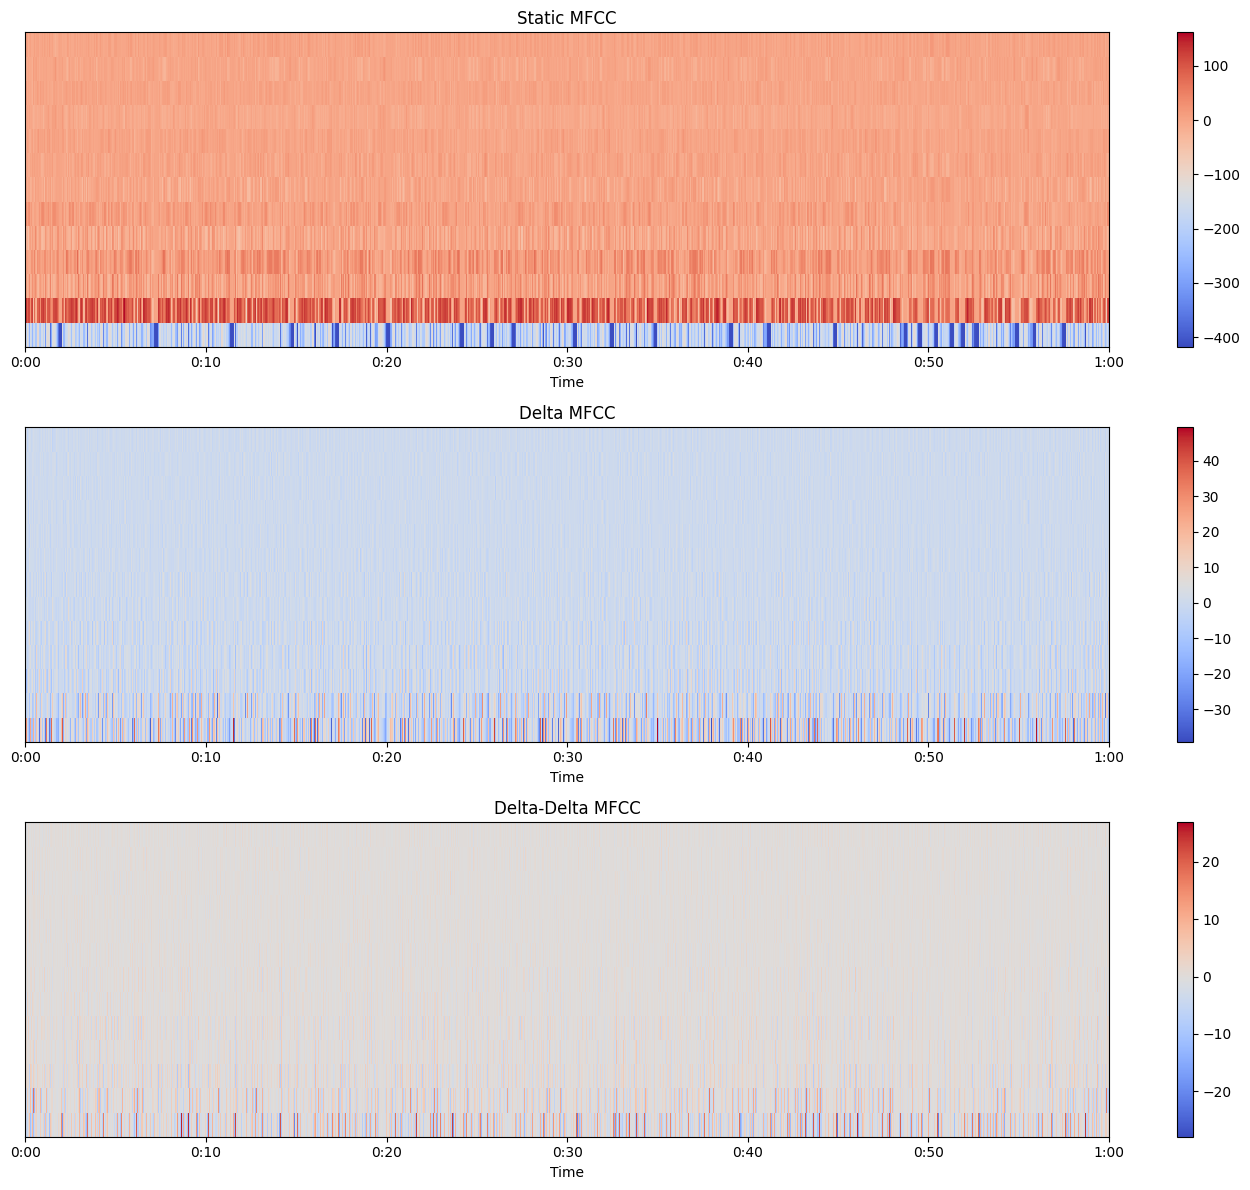

In [10]:
fig, axes = plt.subplots(
    3, 1,
    figsize=(14, 12)
)

matrices = [
    mfcc,
    delta_mfcc,
    delta2_mfcc
]

titles = [
    "Static MFCC",
    "Delta MFCC",
    "Delta-Delta MFCC"
]

for ax, matrix, title in zip(
    axes,
    matrices,
    titles
):

    img = librosa.display.specshow(
        matrix,
        sr=sr,
        hop_length=HOP_LENGTH,
        x_axis="time",
        ax=ax
    )

    ax.set_title(title)
    fig.colorbar(img, ax=ax)

plt.tight_layout()
plt.show()